# Bayesian Black-Box Optimisation — method and results

Eight unknown functions. Each takes a vector of real numbers with every coordinate in the open
unit interval and returns a single scalar, all to be **maximised**. There is no formula, no
gradient and no source code — only the input/output pairs that were paid for, one per function
per week, with thirteen in total.

This notebook reproduces the whole result from the raw records: it loads every observation,
rebuilds the surrogate models, re-scores them, and regenerates the figure and tables used in the
README and the model card. It runs top to bottom in a few minutes.

**Contents**

1. Setup and loading the records
2. Where each function ended up
3. Best value found, by trial
4. Which surrogate model won, and why constrained models beat flexible ones
5. The decision rule — a worked example
6. What the cross-validation score does **not** tell you

Shared implementation lives in `bbo_toolkit.py`; the week-by-week reasoning is in `WEEKLY_LOG.md`.

## 1. Setup and loading the records

Each function keeps two things, deliberately separated so that provenance is always recoverable:

* `initial_inputs.npy` / `initial_outputs.npy` — the space-filling design supplied by the course.
  Immutable, and duplicated unmodified under `initial_data/`.
* `new_trials.csv` — one row per bought trial, appended in submission order and never edited in
  place. A diff of this file shows exactly which observation arrived when.

Loading concatenates the two. Everything downstream treats them identically.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, sys
import matplotlib; import matplotlib.pyplot as plt
sys.path.insert(0, '.')
from bbo_toolkit import fit_surrogate, loo_q2

RANDOM_STATE = 0          # fixed throughout the project

def load(i):
    """Return (X, y, n_initial) for function i: supplied design stacked above bought trials."""
    X0 = np.load(f'function_{i}/initial_inputs.npy')
    y0 = np.load(f'function_{i}/initial_outputs.npy')
    d  = pd.read_csv(f'function_{i}/new_trials.csv')
    Xt = d[[c for c in d.columns if c != 'y']].values
    yt = d['y'].values
    return np.vstack([X0, Xt]), np.concatenate([y0, yt]), len(y0)

for i in range(1, 9):
    X, y, n0 = load(i)
    print(f'Function {i}: {X.shape[1]}-D | {n0} supplied + {len(y)-n0} bought = {len(y)} observations')

Function 1: 2-D | 10 supplied + 12 bought = 22 observations
Function 2: 2-D | 10 supplied + 12 bought = 22 observations
Function 3: 3-D | 15 supplied + 12 bought = 27 observations
Function 4: 4-D | 30 supplied + 11 bought = 41 observations
Function 5: 4-D | 20 supplied + 12 bought = 32 observations
Function 6: 5-D | 20 supplied + 12 bought = 32 observations
Function 7: 6-D | 30 supplied + 12 bought = 42 observations
Function 8: 8-D | 40 supplied + 12 bought = 52 observations


## 2. Where each function ended up

The competition metric is the **best value ever observed**, so the attribution question is how
much of the final figure came from the search rather than from the free starting sample.

Two functions are fitted on a transformed output. Their raw ranges span roughly a hundred and
four orders of magnitude respectively, and no stationary model can describe that on a linear
scale — handling it was the single change that made either of them tractable.

In [2]:
CONFIG = {   # surrogate family, output transform, lengthscale bounds — final settings
    1: ('quadratic', 'log10abs', (0.01, 0.5)),
    2: ('additive',   None,      (0.01, 10.0)),
    3: ('matern',     None,      (0.01, 10.0)),
    4: ('matern',     None,      (0.01, 10.0)),
    5: ('quadratic', 'log',      (0.01, 10.0)),
    6: ('additive',   None,      (0.01, 10.0)),
    7: ('matern',     None,      (0.01, 0.8)),
    8: ('matern',     None,      (0.01, 10.0)),
}

def transform(y, how):
    """Fit-space target. The floor on log10abs is not cosmetic: one reading is exactly 0,
    which produced a negative infinity and crashed the fit until it was added."""
    if how == 'log10abs': return np.log10(np.maximum(np.abs(y), 1e-300))
    if how == 'log':      return np.log(y)
    return y

rows = []
for i in range(1, 9):
    X, y, n0 = load(i)
    rows.append({
        'function': i,
        'dim': X.shape[1],
        'supplied': n0,
        'bought': len(y) - n0,
        'best in supplied design': y[:n0].max(),
        'best found': y.max(),
        'surrogate': CONFIG[i][0],
        'output transform': CONFIG[i][1] or '-',
    })

results = pd.DataFrame(rows).set_index('function')
pd.set_option('display.width', 200)
results

,dim,supplied,bought,best in supplied design,best found,surrogate,output transform
function,,,,,,,
1,2,10,12,7.710875e-16,0.000105,quadratic,log10abs
2,2,10,12,6.112052e-01,0.689468,additive,-
3,3,15,12,-3.483531e-02,-0.025235,matern,-
4,4,30,11,-4.025542e+00,0.602754,matern,-
5,4,20,12,1.088860e+03,8662.405001,quadratic,log
6,5,20,12,-7.142649e-01,-0.249746,additive,-
7,6,30,12,1.364968e+00,2.748654,matern,-
8,8,40,12,9.598482e+00,9.974458,matern,-


In [3]:
# Where the best point sits, per function
for i in range(1, 9):
    X, y, _ = load(i)
    print(f'F{i}  y = {y.max():>12.6g}   at  ' + ', '.join(f'{v:.6f}' for v in X[np.argmax(y)]))

F1  y =  0.000105167   at  0.582509, 0.681526
F2  y =     0.689468   at  0.712637, 0.826564
F3  y =    -0.025235   at  0.999999, 0.580426, 0.859784
F4  y =     0.602754   at  0.407583, 0.416930, 0.360748, 0.432592
F5  y =      8662.41   at  0.999999, 0.999999, 0.999999, 0.999999
F6  y =    -0.249746   at  0.422422, 0.453026, 0.694051, 0.794604, 0.000001
F7  y =      2.74865   at  0.000001, 0.154956, 0.492485, 0.255685, 0.345436, 0.698119
F8  y =      9.97446   at  0.108546, 0.163472, 0.141025, 0.000001, 0.863819, 0.487005, 0.208507, 0.599440


Three of Function 5's four inputs sit on the upper boundary and the fourth reached it too — its
optimum is a **vertex of the feasible box**, not an interior peak. Several other functions also
pin at least one coordinate to a boundary. That was not what I expected going in, and it changes
what "refining" even means on those axes.

## 3. Best value found, by trial

The blue line is the running best; grey dots are the individual readings, which makes the cost of
a wrong step visible. Each panel has its own scale because the functions differ by orders of
magnitude — Function 1 is plotted logarithmically.

saved image.png


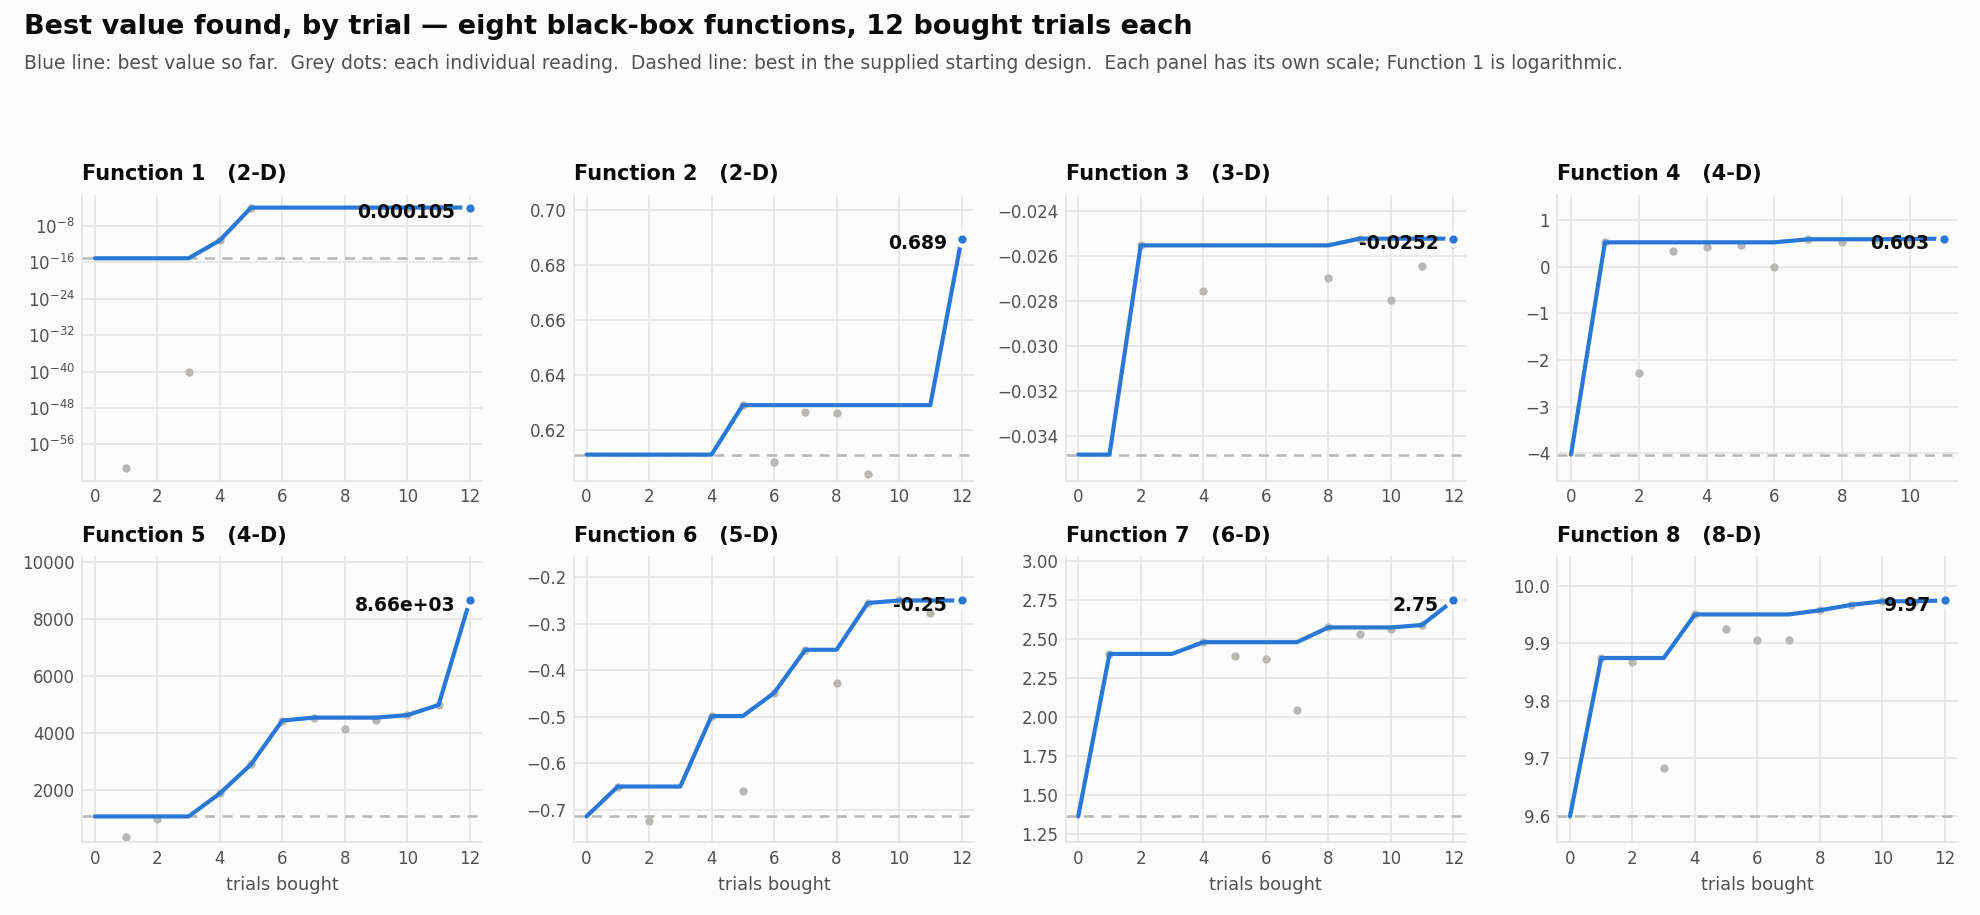

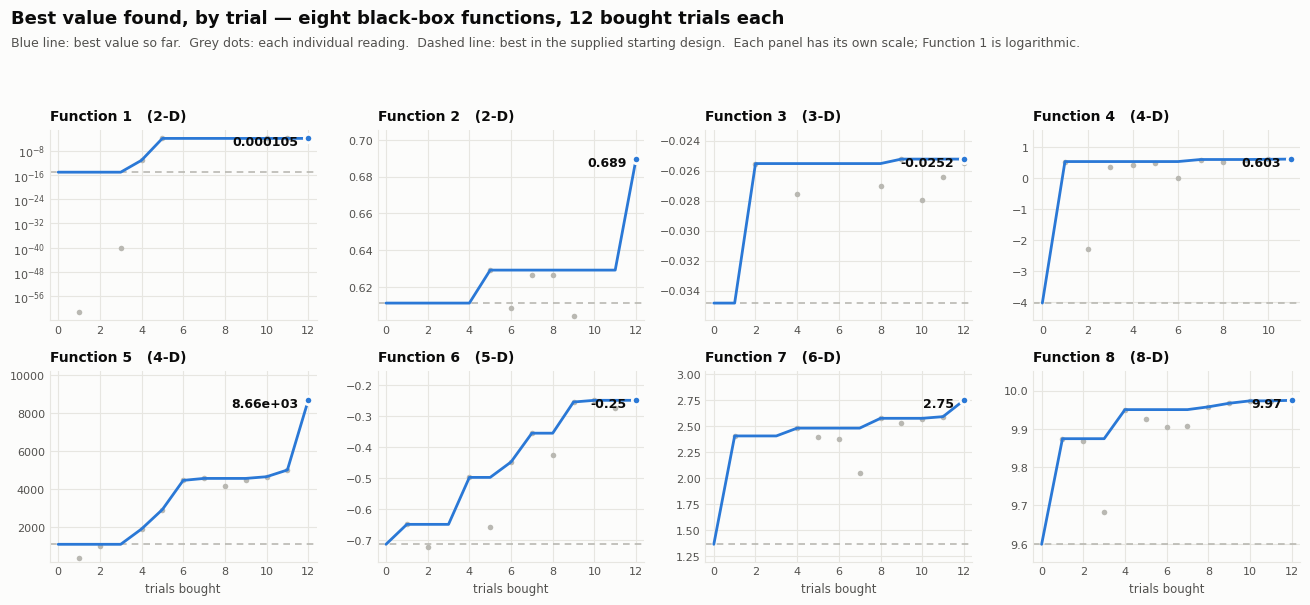

In [4]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

SURFACE='#fcfcfb'; INK='#0b0b0b'; INK2='#52514e'; SERIES='#2a78d6'; MUTED='#b9b8b2'; GRID='#e7e6e1'

def _series(i):
    y0=np.load(f'function_{i}/initial_outputs.npy')
    d=pd.read_csv(f'function_{i}/new_trials.csv')
    return float(y0.max()), d['y'].values

DIMS={1:2,2:2,3:3,4:4,5:4,6:5,7:6,8:8}
LOGY={1}

fig,axes=plt.subplots(2,4,figsize=(13.2,6.1),facecolor=SURFACE)
for k,ax in enumerate(axes.ravel()):
    i=k+1
    init,yt=_series(i)
    run=np.maximum.accumulate(np.concatenate([[init],yt]))
    x=np.arange(len(run))                       # 0 = supplied design, 1..n = bought trials
    ax.set_facecolor(SURFACE)
    ax.grid(True,color=GRID,linewidth=0.8,zorder=0)
    ax.set_axisbelow(True)
    ax.axhline(init,color=MUTED,linewidth=1.2,linestyle=(0,(4,3)),zorder=1)
    # individual readings, only those that fall inside the visible band
    lo,hi=run.min(),run.max(); pad=(hi-lo)*0.12 if hi>lo else abs(hi)*0.12+1e-12
    vis=(yt>=lo-pad)
    ax.scatter(np.arange(1,len(yt)+1)[vis],yt[vis],s=16,color=MUTED,zorder=2,linewidths=0)
    ax.plot(x,run,color=SERIES,linewidth=2,zorder=3,solid_capstyle='round')
    ax.plot(x[-1],run[-1],'o',color=SERIES,markersize=6,zorder=4,
            markeredgecolor=SURFACE,markeredgewidth=2)
    if i in LOGY:
        ax.set_yscale('log')
    else:
        ax.set_ylim(lo-pad,hi+pad*1.7)
    lab = f'{run[-1]:.3g}'
    ax.annotate(lab,(x[-1],run[-1]),textcoords='offset points',xytext=(-7,-5),
                ha='right',fontsize=9,color=INK,fontweight='bold')
    ax.set_title(f'Function {i}   ({DIMS[i]}-D)',fontsize=10,color=INK,loc='left',pad=7,fontweight='bold')
    ax.tick_params(labelsize=8,colors=INK2,length=0)
    for s in ('top','right'): ax.spines[s].set_visible(False)
    for s in ('left','bottom'): ax.spines[s].set_color(GRID)
    if k>=4: ax.set_xlabel('trials bought',fontsize=8.5,color=INK2)
    ax.set_xlim(-0.4,len(run)-0.6)

fig.suptitle('Best value found, by trial — eight black-box functions, 12 bought trials each',
             fontsize=13,color=INK,x=0.012,ha='left',y=0.985,fontweight='bold')
fig.text(0.012,0.925,'Blue line: best value so far.  Grey dots: each individual reading.  '
                     'Dashed line: best in the supplied starting design.  Each panel has its own scale; Function 1 is logarithmic.',
         fontsize=9,color=INK2,ha='left')
fig.tight_layout(rect=[0,0,1,0.90])
fig.savefig('image.png',dpi=150,facecolor=SURFACE)
print('saved image.png')

from IPython.display import Image, display
display(Image('image.png'))

Notice the shape of these curves. They are **staircases**, not smooth climbs: long flat stretches
punctuated by a few large steps. And the big steps cluster in the rounds where I overrode the
model rather than the rounds where I tuned it — Function 5's last two jumps and Function 1's
early climb are both the result of backing direct readings against a confident surrogate.

## 4. Which surrogate won, and why constrained models beat flexible ones

Three families compete every round, scored by **leave-one-out cross-validation** (Q²): remove one
observation, refit, predict it, repeat across all observations. Q² of 1 is perfect prediction of a
point never seen, 0 is no better than always guessing the mean, negative is worse than that.

* **Matérn 5/2** with a lengthscale per input — flexible, the usual default.
* **Additive GP** — a sum of one-dimensional kernels, which *forbids* interactions between inputs.
* **Quadratic trend + GP residual** — a polynomial for global curvature, a GP for the uncertainty
  a bare polynomial cannot supply.

A challenger only replaces the incumbent on a margin of about 0.1; below that the difference is
cross-validation noise at these sample sizes.

*This cell refits every family on every function and takes a few minutes.*

In [5]:
scores = []
for i in range(1, 9):
    X, y, _ = load(i)
    kind, how, lsb = CONFIG[i]
    yf = transform(y, how)
    row = {'function': i, 'in use': kind}
    for family in ('matern', 'additive', 'quadratic'):
        row[family] = round(float(loo_q2(X, yf, kind=family,
                                         length_scale_bounds=lsb,
                                         random_state=RANDOM_STATE)), 3)
    scores.append(row)
    print(f'scored F{i}', flush=True)

q2 = pd.DataFrame(scores).set_index('function')[['matern', 'additive', 'quadratic', 'in use']]
q2

scored F1


scored F2


scored F3


scored F4


scored F5


scored F6


scored F7


scored F8


,matern,additive,quadratic,in use
function,,,,
1,0.595,0.136,0.915,quadratic
2,0.390,0.689,-0.569,additive
3,0.130,0.072,0.059,matern
4,0.980,0.969,0.955,matern
5,0.662,0.685,0.803,quadratic
6,0.722,0.901,0.894,additive
7,0.944,0.807,0.735,matern
8,0.996,1.000,0.999,matern


In [6]:
winner = q2[['matern', 'additive', 'quadratic']].idxmax(axis=1)
print('Best-scoring family per function:')
print(winner.to_string())
print()
print(winner.value_counts().to_string())

Best-scoring family per function:
function
1    quadratic
2     additive
3       matern
4       matern
5    quadratic
6     additive
7       matern
8     additive

additive     3
matern       3
quadratic    2


**A constrained family wins on half the functions.** That ran against my expectations at the
start: I assumed the Gaussian process's flexibility was an asset. With thirty-odd observations it
is a liability, because flexibility gets spent fitting noise. A strong assumption that is only
approximately right — "these inputs do not interact", "this is a quadratic on a log scale" — is
worth more than no assumption when you cannot afford the data to earn one.

Function 3 is the honest failure. No family exceeds about 0.13, meaning that after twelve bought
trials none of these models can predict it meaningfully. The correct response to that is not to
trust the model anyway but to restrict what it is allowed to decide, which is what the next
section describes.

## 5. The decision rule — a worked example

The Q² score decides **not what the next point is, but who chooses it**:

| Q² | Authority | Mechanism |
|---|---|---|
| above ~0.7 | the model chooses a location | acquisition maximised over a trust region |
| ~0 to 0.7 | the model ranks, it does not choose | a dozen small steps built geometrically; the model only orders them |
| ~0 or below | the model chooses nothing | the trial goes to measurement instead |

Promotion and demotion both follow the score, re-measured weekly, so a tier is a current
measurement rather than a standing verdict about a function.

Function 4 is the instructive case. It scores ~0.98 and was still restricted to *ranking* — the
cell below shows why.

In [7]:
i = 4
X, y, _ = load(i)
kind, how, lsb = CONFIG[i]
model = fit_surrogate(X, transform(y, how), kind=kind, length_scale_bounds=lsb,
                      random_state=RANDOM_STATE, n_restarts_optimizer=10)

# the fitted lengthscales say the surface varies slowly ...
ls = [v for p, v in model.kernel_.get_params().items()
      if p.endswith('length_scale') and not p.endswith('bounds')]
print('fitted lengthscales :', np.round(np.atleast_1d(ls[0]).astype(float), 3))

# ... but three readings differing ONLY in the second input say otherwise
best = X[np.argmax(y)]
slice_ = [(X[j, 1], y[j]) for j in range(len(y))
          if np.allclose(np.delete(X[j], 1), np.delete(best, 1))]
print('\nreadings differing only in input 2:')
for a, b in sorted(slice_):
    print(f'   x1 = {a:.6f}   y = {b:.7f}')

span = max(s[0] for s in slice_) - min(s[0] for s in slice_)
rise = max(s[1] for s in slice_) - min(s[1] for s in slice_)
print(f'\nlocal gradient from measurement: {rise/span:.1f} per unit of distance')
print('the lengthscales imply something roughly an order of magnitude smoother.')

fitted lengthscales : [1.353 0.923 0.945 1.116]

readings differing only in input 2:
   x1 = 0.411177   y = 0.5895267
   x1 = 0.416930   y = 0.6027542
   x1 = 0.421177   y = 0.5958135
   x1 = 0.422760   y = 0.5891556

local gradient from measurement: 1.2 per unit of distance
the lengthscales imply something roughly an order of magnitude smoother.


That mismatch is the whole difficulty with Function 4: a **narrow spike sitting on a smooth
background**. The cross-validation score of 0.98 is earned on the thirty spread-out initial
points and says nothing about the peak, which is exactly where every decision is made. Tightening
the kernel does not fix it — tested, and the score falls to about 0.85 — because the smooth
background is real too, and one lengthscale cannot describe both.

The practical consequence, learned the expensive way: **size steps from measured differences, not
from fitted hyperparameters.** Six consecutive attempts on this function failed to beat its very
first trial. The seventh succeeded, once the step size came from "0.012 gained, 0.024 lost"
instead of from the model's own numbers.

## 6. What the cross-validation score does *not* tell you

This is the most important finding in the project, and the one that generalises furthest beyond
it.

Cross-validation removes a point from a data set the model already has and asks it to predict
that point back — it measures **interpolation**. But every query is an **extrapolation**: by
construction it goes somewhere the model has never been. A score can therefore be excellent and
still say nothing useful about the decision it is being used to justify.

Two concrete instances from this project:

* **Function 8** scores 0.996 — the best-modelled function of the eight — and over-predicted its
  own proposal on **seven consecutive rounds**, by about 0.09 on average. That is bias, not noise,
  and no Q² could see it. Halving the exploration weight did not fix it, because the bias was in
  the model rather than in the acquisition; setting the weight to zero did.
* **Function 4** scores 0.980, as section 5 showed, while over-smoothing its own peak more than
  tenfold.

The two best-scoring models were the two worst-behaved. The partial remedy is cheap and I added
it far too late: **track predicted against realised for every point you actually buy.** It is the
only diagnostic that tests extrapolation, and it is the single change I would make earliest if I
started again.

In [8]:
print(f'Final position across all eight functions\n' + '-'*46)
for i in range(1, 9):
    X, y, n0 = load(i)
    start, end = y[:n0].max(), y.max()
    print(f'F{i} ({X.shape[1]}-D):  {start:>12.6g}  ->  {end:>12.6g}')
print('-'*46)
print('All eight improved on the supplied starting design.')

Final position across all eight functions
----------------------------------------------
F1 (2-D):   7.71088e-16  ->   0.000105167
F2 (2-D):      0.611205  ->      0.689468
F3 (3-D):    -0.0348353  ->     -0.025235
F4 (4-D):      -4.02554  ->      0.602754
F5 (4-D):       1088.86  ->       8662.41
F6 (5-D):     -0.714265  ->     -0.249746
F7 (6-D):       1.36497  ->       2.74865
F8 (8-D):       9.59848  ->       9.97446
----------------------------------------------
All eight improved on the supplied starting design.
